# Ridge and Lasso regularisation

Fit a high-degree polynomial to noisy observations. Compare ordinary least squares with Ridge and Lasso and see what happens to held-out error and to the polynomial weights.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.polynomial.chebyshev import chebvander
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(16)
def trend(x):
    return 0.52 - 0.27 * np.sin(2 * np.pi * x)

x_train = np.linspace(0.12, 0.88, 18)
x_test = np.linspace(0.025, 0.975, 21)
y_train = trend(x_train) + rng.normal(0, 0.05, x_train.size)
y_test = trend(x_test) + rng.normal(0, 0.025, x_test.size)

degree = 9
def features(x):
    return chebvander(2 * x - 1, degree)[:, 1:]

## Compare the fits

The scaler learns each feature's center and spread from the training set only. The intercept is not penalized. Scikit-learn's Ridge uses the **sum** of squared errors, so multiply the notebook's per-point alpha by the number of training points when passing it to Ridge.

In [2]:
alpha = 0.01
estimators = {
    "No penalty": LinearRegression(),
    "Ridge": Ridge(alpha=alpha * x_train.size),
    "Lasso": Lasso(alpha=alpha, max_iter=20_000),
}
models = {}
for label, estimator in estimators.items():
    model = make_pipeline(StandardScaler(), estimator)
    models[label] = model.fit(features(x_train), y_train)
    train_error = mean_squared_error(y_train, model.predict(features(x_train)))
    test_error = mean_squared_error(y_test, model.predict(features(x_test)))
    zeros = np.count_nonzero(estimator.coef_ == 0)
    print(f"{label:10s} train MSE {train_error:.4f} | test MSE {test_error:.4f} | zero weights {zeros}")

No penalty train MSE 0.0005 | test MSE 0.0722 | zero weights 0
Ridge      train MSE 0.0005 | test MSE 0.0022 | zero weights 0
Lasso      train MSE 0.0008 | test MSE 0.0033 | zero weights 6


## See it

Look at the ends of the fitted curves and compare the weights. Try raising or lowering alpha and running the fit and plots again. Ridge shrinks weights, while Lasso can set some weights to exactly zero.

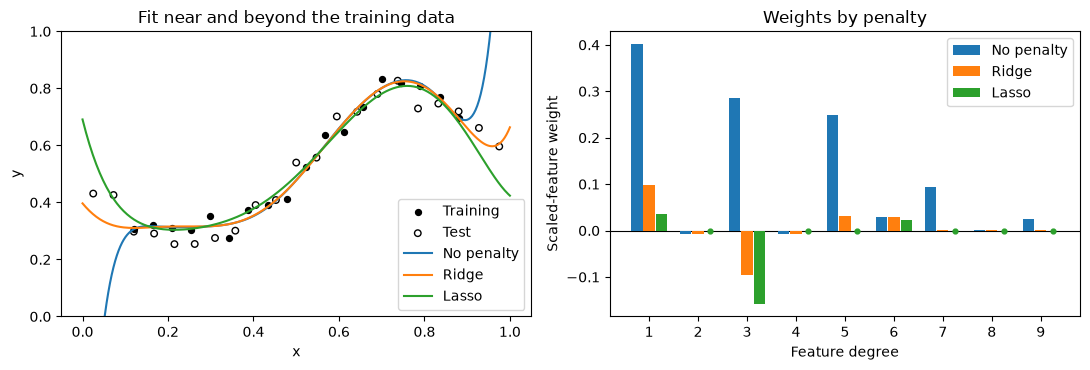

In [3]:
dense = np.linspace(0, 1, 250)
fig, (curves, weights) = plt.subplots(1, 2, figsize=(11, 3.8))
curves.scatter(x_train, y_train, s=18, color="black", label="Training")
curves.scatter(x_test, y_test, s=22, facecolors="none", edgecolors="black", label="Test")
for index, (label, model) in enumerate(models.items()):
    line, = curves.plot(dense, model.predict(features(dense)), label=label)
    offsets = np.arange(1, degree + 1) + (index - 1) * 0.25
    coefficients = model.steps[-1][1].coef_
    weights.bar(offsets, coefficients, width=0.23, color=line.get_color(), label=label)
    zero = coefficients == 0
    weights.scatter(offsets[zero], coefficients[zero], s=12, color=line.get_color())
curves.set(xlabel="x", ylabel="y", title="Fit near and beyond the training data", ylim=(0, 1))
curves.legend()
weights.axhline(0, linewidth=0.8, color="black", zorder=0)
weights.set(xlabel="Feature degree", ylabel="Scaled-feature weight", title="Weights by penalty", xticks=range(1, degree + 1))
weights.legend()
fig.tight_layout()
plt.show()